In [1]:
# Data Handling
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# Natural Language Processing
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import string

# Download NLTK resources (only needs to be done once)
nltk.download('vader_lexicon')
nltk.download('stopwords')
nltk.download('punkt')

# Set plot style
sns.set(style='whitegrid')

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\Bhabishya\AppData\Roaming\nltk_data...
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Bhabishya\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Bhabishya\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


In [2]:
# Load the dataset
df = pd.read_csv('reviews.csv', index_col=0)

# Drop rows with missing review text, as they are essential for this analysis
df.dropna(subset=['Review Text'], inplace=True)

# Keep only the columns we need
df = df[['Review Text', 'Rating', 'Recommended IND']].copy()

# Display the first few rows and info
print("First 5 rows:")
display(df.head())
print("\nDataset Info:")
df.info()

First 5 rows:


,Review Text,Rating,Recommended IND
0,Absolutely wonderful - silky and sexy and comf...,4,1
1,Love this dress! it's sooo pretty. i happene...,5,1
2,I had such high hopes for this dress and reall...,3,0
3,"I love, love, love this jumpsuit. it's fun, fl...",5,1
4,This shirt is very flattering to all due to th...,5,1



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
Index: 22641 entries, 0 to 23485
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Review Text      22641 non-null  object
 1   Rating           22641 non-null  int64 
 2   Recommended IND  22641 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 707.5+ KB


In [3]:
# Initialize the VADER sentiment intensity analyzer
sia = SentimentIntensityAnalyzer()

# Get the compound sentiment score for each review
# A score >= 0.05 is positive, <= -0.05 is negative, and in between is neutral.
df['Sentiment Score'] = df['Review Text'].apply(lambda review: sia.polarity_scores(review)['compound'])

# Classify the sentiment based on the score
def classify_sentiment(score):
    if score >= 0.05:
        return 'Positive'
    elif score <= -0.05:
        return 'Negative'
    else:
        return 'Neutral'

df['Sentiment'] = df['Sentiment Score'].apply(classify_sentiment)

# Display the results
print("Sentiment Analysis Results:")
display(df[['Review Text', 'Sentiment Score', 'Sentiment']].head())

# Show the distribution of sentiments
print("\nSentiment Distribution:")
print(df['Sentiment'].value_counts())

Sentiment Analysis Results:


,Review Text,Sentiment Score,Sentiment
0,Absolutely wonderful - silky and sexy and comf...,0.8932,Positive
1,Love this dress! it's sooo pretty. i happene...,0.9729,Positive
2,I had such high hopes for this dress and reall...,0.9427,Positive
3,"I love, love, love this jumpsuit. it's fun, fl...",0.5727,Positive
4,This shirt is very flattering to all due to th...,0.9291,Positive



Sentiment Distribution:
Sentiment
Positive    20987
Negative     1376
Neutral       278
Name: count, dtype: int64


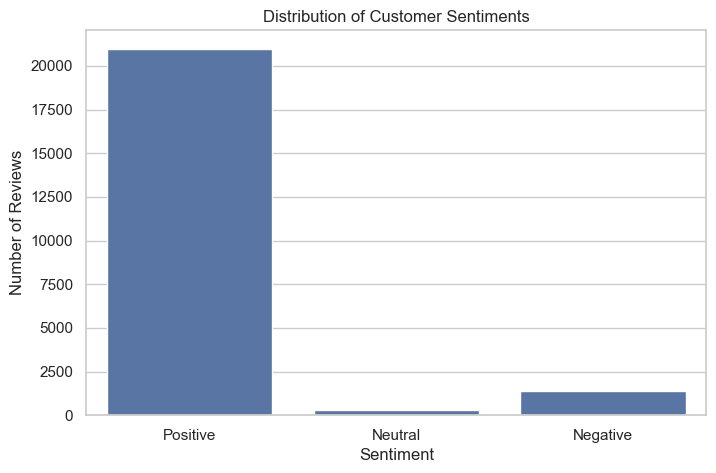

In [4]:
# Plot the sentiment distribution
plt.figure(figsize=(8, 5))
sns.countplot(x='Sentiment', data=df, order=['Positive', 'Neutral', 'Negative'])
plt.title('Distribution of Customer Sentiments')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.show()

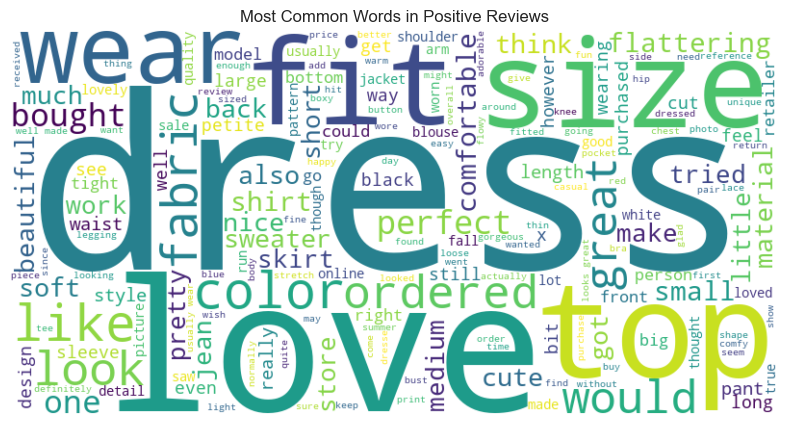

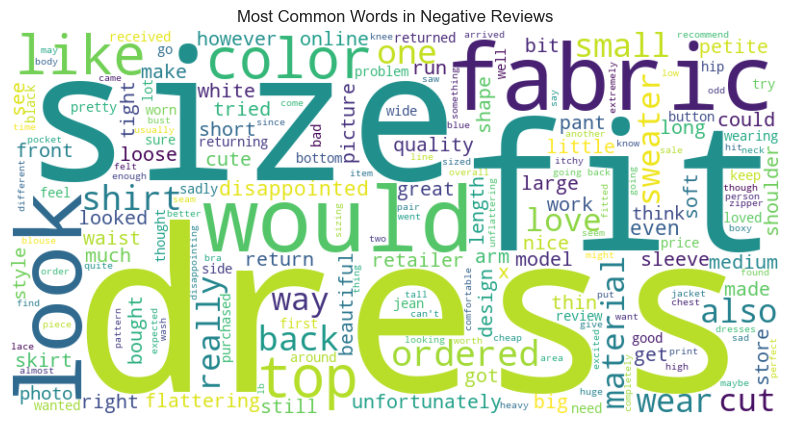

In [5]:
# Get English stopwords
stop_words = set(stopwords.words('english'))

def generate_word_cloud(text, title):
    wordcloud = WordCloud(width=800, height=400, background_color='white',
                          stopwords=stop_words, min_font_size=10).generate(text)
    
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(title)
    plt.show()

# Combine all positive reviews into a single string
positive_text = ' '.join(df[df['Sentiment'] == 'Positive']['Review Text'])
generate_word_cloud(positive_text, 'Most Common Words in Positive Reviews')

# Combine all negative reviews into a single string
negative_text = ' '.join(df[df['Sentiment'] == 'Negative']['Review Text'])
generate_word_cloud(negative_text, 'Most Common Words in Negative Reviews')

## Business Insights from Sentiment Analysis

This analysis of customer reviews provides several key insights:

1.  **Overwhelmingly Positive Feedback:** The vast majority of reviews are positive, indicating high overall product satisfaction.

2.  **Positive Drivers:** The positive word cloud is dominated by terms like **"love," "great," "fit," "flattering," "comfortable," and "perfect."** This suggests that customers value the style, comfort, and accurate sizing of the clothing. Marketing efforts should highlight these attributes.

3.  **Negative Drivers:** The negative word cloud frequently features words like **"small," "fabric," "disappointed," "return," and "cheap."** This indicates that key issues are related to items running smaller than expected and poor material quality. The business should prioritize accurate sizing charts and be transparent about fabric composition to reduce returns and negative feedback.